# Práctica: LSTM con atención de Bahdanau

**Procesamiento del Lenguaje Natural**

Partimos del modelo seq2seq con *feedback* del notebook anterior (traducción inglés → español con LSTM) y le añadimos la **atención aditiva de Bahdanau** et al. (2014).

En cada paso $i$ el decodificador calcula un vector de contexto $c_i$ como media ponderada de todas las anotaciones $h_j$ del codificador:

$$c_i=\sum_{j=1}^{T_x}\alpha_{ij}\,h_j,\qquad \alpha_{ij}=\frac{\exp(e_{ij})}{\sum_{k=1}^{T_x}\exp(e_{ik})},\qquad e_{ij}=v_a^{\top}\tanh\big(W_1[s_{i-1};h_j]\big)$$

Se entrenan dos modelos con **el mismo procedimiento** (mismos datos, hiperparámetros y semilla): el seq2seq **sin atención** del notebook anterior y el seq2seq **con atención**, y se comparan.

## 0. Configuración

In [17]:
from pathlib import Path
from collections import Counter
from itertools import zip_longest
import math
import random
import re
import time

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# CPU también funciona. Las GPU NVIDIA se usan si están disponibles.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

Dispositivo: cpu


## 1. Datos

Igual que en el notebook anterior: pares alineados de **Europarl** (inglés → español), con la longitud y el número de ejemplos limitados. Se eliminan los pares duplicados y se parte por frase de origen en entrenamiento y prueba, de modo que una misma entrada no aparece en las dos particiones.

Los ficheros `europarl-v7.es-en.en` y `europarl-v7.es-en.es` deben estar en `data/europarl/`.

In [18]:
SOURCE_FILE = Path("data/europarl/europarl-v7.es-en.en")
TARGET_FILE = Path("data/europarl/europarl-v7.es-en.es")
MAX_WORDS = 30             # Sin contar los tokens especiales.
MAX_PAIRS = 30_000         # Usa None para conservar todos los pares válidos.
MIN_FREQUENCY = 2
MAX_VOCAB_SIZE = 12_000    # Incluye los cuatro tokens especiales.


def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower(), flags=re.UNICODE)


def read_pairs(source_file, target_file, max_words, max_pairs):
    pairs = []
    seen = set()
    with source_file.open(encoding="utf-8") as source, target_file.open(encoding="utf-8") as target:
        for line_number, (en, es) in enumerate(zip_longest(source, target), start=1):
            if en is None or es is None:
                raise ValueError(f"Ficheros desalineados en la línea {line_number}")
            en_tokens, es_tokens = tokenize(en), tokenize(es)
            if not (1 <= len(en_tokens) <= max_words and 1 <= len(es_tokens) <= max_words):
                continue
            pair = (tuple(en_tokens), tuple(es_tokens))
            if pair in seen:
                continue
            seen.add(pair)
            pairs.append(pair)
            if max_pairs is not None and len(pairs) >= max_pairs:
                break
    return pairs


def split_pairs(pairs, seed, test_fraction=0.1):
    sources = sorted({en for en, es in pairs})
    random.Random(seed).shuffle(sources)
    test_sources = set(sources[:max(1, int(test_fraction * len(sources)))])
    train = [pair for pair in pairs if pair[0] not in test_sources]
    test = [pair for pair in pairs if pair[0] in test_sources]
    return train, test


pairs = read_pairs(SOURCE_FILE, TARGET_FILE, MAX_WORDS, MAX_PAIRS)
train_pairs, test_pairs = split_pairs(pairs, SEED)
print("Pares de entrenamiento y prueba:", len(train_pairs), len(test_pairs))
print("Ejemplo:", train_pairs[0])

Pares de entrenamiento y prueba: 26993 3007
Ejemplo: (('resumption', 'of', 'the', 'session'), ('reanudación', 'del', 'período', 'de', 'sesiones'))


### Vocabulario y *data loaders*

Los identificadores especiales son iguales en ambos idiomas: `<pad>` rellena los lotes, `<sos>` inicia la entrada del decoder, `<eos>` marca el final y `<unk>` representa palabras desconocidas.

In [19]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3
SPECIAL_TOKENS = ["<pad>", "<sos>", "<eos>", "<unk>"]


class Vocabulary:
    def __init__(self, sentences, min_frequency, max_size):
        counts = Counter(token for sentence in sentences for token in sentence)
        words = [word for word, count in counts.most_common()
                 if count >= min_frequency and word not in SPECIAL_TOKENS]
        self.itos = SPECIAL_TOKENS + words[:max_size - len(SPECIAL_TOKENS)]
        self.stoi = {word: index for index, word in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(token, UNK) for token in tokens]

    def decode(self, ids):
        words = []
        for index in ids:
            if index == EOS:
                break
            if index not in (PAD, SOS):
                words.append(self.itos[index])
        return words


src_vocab = Vocabulary((en for en, es in train_pairs), MIN_FREQUENCY, MAX_VOCAB_SIZE)
tgt_vocab = Vocabulary((es for en, es in train_pairs), MIN_FREQUENCY, MAX_VOCAB_SIZE)


class TranslationDataset(Dataset):
    def __init__(self, pairs, src_vocab, tgt_vocab):
        self.examples = []
        for en, es in pairs:
            source = torch.tensor(src_vocab.encode(en) + [EOS], dtype=torch.long)
            target = torch.tensor([SOS] + tgt_vocab.encode(es) + [EOS], dtype=torch.long)
            self.examples.append((source, target))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]


def collate_batch(examples):
    sources, targets = zip(*examples)
    source_lengths = torch.tensor([len(source) for source in sources])
    sources = pad_sequence(sources, batch_first=True, padding_value=PAD)
    targets = pad_sequence(targets, batch_first=True, padding_value=PAD)
    return sources, source_lengths, targets


BATCH_SIZE = 32
train_dataset = TranslationDataset(train_pairs, src_vocab, tgt_vocab)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_batch,
                          generator=torch.Generator().manual_seed(SEED))

print("Vocabularios inglés/español:", len(src_vocab), len(tgt_vocab))


def unknown_rate(pairs, vocab, language_index):
    tokens = [token for pair in pairs for token in pair[language_index]]
    return sum(token not in vocab.stoi for token in tokens) / len(tokens)


print(f"Palabras desconocidas en prueba (EN): {unknown_rate(test_pairs, src_vocab, 0):.1%}")
print(f"Palabras desconocidas en prueba (ES): {unknown_rate(test_pairs, tgt_vocab, 1):.1%}")

Vocabularios inglés/español: 8808 12000
Palabras desconocidas en prueba (EN): 1.9%
Palabras desconocidas en prueba (ES): 3.4%


## 2. Atención de Bahdanau

Implementación del enunciado. Para cada posición $j$ de la frase origen:

$$e_{ij}=v_a^{\top}\tanh\big(W_1[s_{i-1};h_j]\big)$$

- `W1` es una capa lineal sobre la **concatenación** $[s_{i-1};h_j]$ que la proyecta a un espacio intermedio (`attention_dim`).
- `tanh` introduce la no linealidad.
- `v` (capa lineal sin sesgo a 1 dimensión) colapsa el resultado a un escalar $e_{ij}$.
- `softmax` sobre las posiciones $j$ da $\alpha_{ij}$. Las posiciones de **relleno** se ponen a $-\infty$ antes, para que reciban peso 0.
- El contexto es $c_i=\sum_j\alpha_{ij}h_j$, que se calcula con `torch.bmm` (producto matricial por lotes).

In [20]:
class BahdanauAttention(nn.Module):
    def __init__(self, decoder_dim, encoder_dim, attention_dim):
        super().__init__()
        self.W1 = nn.Linear(decoder_dim + encoder_dim, attention_dim)   # actúa sobre [s_{i-1}; h_j]
        self.v = nn.Linear(attention_dim, 1, bias=False)                # v_a

    def forward(self, state, annotations, mask):
        # state: (lote, decoder_dim) = s_{i-1} | annotations: (lote, Tx, encoder_dim) = h_j
        # mask: (lote, Tx), True = token real
        Tx = annotations.size(1)
        state = state.unsqueeze(1).expand(-1, Tx, -1)                              # (lote, Tx, decoder_dim)
        scores = self.v(torch.tanh(self.W1(torch.cat([state, annotations], dim=-1))))  # (lote, Tx, 1)
        scores = scores.squeeze(-1).masked_fill(~mask, float("-inf"))              # e_ij: (lote, Tx)
        weights = F.softmax(scores, dim=-1)                                        # alpha_ij: (lote, Tx)
        context = torch.bmm(weights.unsqueeze(1), annotations).squeeze(1)          # c_i: (lote, encoder_dim)
        return context, weights

## 3. Modelo seq2seq (con y sin atención)

Misma estructura que el notebook anterior (LSTM de varias capas, *teacher forcing* por paso, generación voraz). Cambios para la atención:

- **Encoder:** además del estado final, devuelve **todas las salidas** $h_1,\dots,h_{T_x}$ (las anotaciones).
- **Decoder:** con `use_attention=True`, en cada paso usa el estado de la última capa $s_{i-1}$ para calcular $c_i$, y alimenta la LSTM con $[\text{emb}(y_{i-1});c_i]$. Los logits se calculan a partir de $s_i$, igual que sin atención. Con `use_attention=False` es exactamente el decoder del notebook anterior.
- **`generate`** puede devolver también los pesos de atención.

In [21]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim,
                            num_layers=num_layers, batch_first=True)

    def forward(self, source, source_lengths):
        embedded = self.embedding(source)
        packed = pack_padded_sequence(embedded, source_lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        packed_outputs, (hidden, cell) = self.lstm(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True,
                                         total_length=source.size(1))   # anotaciones h_j
        return outputs, hidden, cell


class Decoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers,
                 attention_dim=None, use_attention=True):
        super().__init__()
        self.use_attention = use_attention
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        context_dim = hidden_dim if use_attention else 0
        if use_attention:
            self.attention = BahdanauAttention(hidden_dim, hidden_dim, attention_dim)
        self.lstm = nn.LSTM(embedding_dim + context_dim, hidden_dim,
                            num_layers=num_layers, batch_first=True)
        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, token_ids, hidden, cell, annotations=None, mask=None):
        embedded = self.embedding(token_ids)                    # (lote, embedding_dim)
        weights = None
        if self.use_attention:
            context, weights = self.attention(hidden[-1], annotations, mask)   # s_{i-1}: última capa
            lstm_input = torch.cat([embedded, context], dim=-1)
        else:
            lstm_input = embedded
        output, (hidden, cell) = self.lstm(lstm_input.unsqueeze(1), (hidden, cell))
        return self.output_layer(output[:, 0, :]), hidden, cell, weights


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, source, source_lengths, target, teacher_forcing_ratio=0.5):
        annotations, hidden, cell = self.encoder(source, source_lengths)
        mask = source != PAD
        token_ids = target[:, 0]  # <sos>
        outputs = []

        for step in range(1, target.size(1)):
            logits, hidden, cell, _ = self.decoder(token_ids, hidden, cell, annotations, mask)
            outputs.append(logits)
            if random.random() < teacher_forcing_ratio:
                token_ids = target[:, step]
            else:
                token_ids = logits.argmax(dim=-1)

        # (lote, longitud_objetivo_sin_sos, vocabulario_español)
        return torch.stack(outputs, dim=1)

    @torch.no_grad()
    def generate(self, source, source_lengths, max_new_tokens=50, return_attention=False):
        # El llamador debe activar model.eval(). No se utiliza la traducción real.
        annotations, hidden, cell = self.encoder(source, source_lengths)
        mask = source != PAD
        batch_size = source.size(0)
        token_ids = torch.full((batch_size,), SOS, dtype=torch.long, device=source.device)
        finished = torch.zeros(batch_size, dtype=torch.bool, device=source.device)
        predictions, attentions = [], []

        for _ in range(max_new_tokens):
            logits, hidden, cell, weights = self.decoder(token_ids, hidden, cell, annotations, mask)
            # <pad> y <sos> no son palabras que deban generarse.
            logits[:, PAD] = -torch.inf
            logits[:, SOS] = -torch.inf
            next_ids = logits.argmax(dim=-1)
            next_ids = torch.where(finished, PAD, next_ids)
            predictions.append(next_ids)
            if weights is not None:
                attentions.append(weights)
            finished = finished | (next_ids == EOS)
            token_ids = next_ids
            if finished.all().item():
                break

        predictions = torch.stack(predictions, dim=1)
        if return_attention:
            return predictions, torch.stack(attentions, dim=1)     # (lote, pasos, Tx)
        return predictions


EMBEDDING_DIM = 128
HIDDEN_DIM = 256
ATTENTION_DIM = 128
NUM_LAYERS = 2


def build_model(use_attention):
    torch.manual_seed(SEED)
    encoder = Encoder(len(src_vocab), EMBEDDING_DIM, HIDDEN_DIM, NUM_LAYERS)
    decoder = Decoder(len(tgt_vocab), EMBEDDING_DIM, HIDDEN_DIM, NUM_LAYERS,
                      ATTENTION_DIM, use_attention)
    return Seq2Seq(encoder, decoder).to(DEVICE)


for name, flag in [("Sin atención", False), ("Con atención", True)]:
    print(f"{name}: {sum(p.numel() for p in build_model(flag).parameters()):,} parámetros")

Sin atención: 7,590,624 parámetros
Con atención: 7,918,560 parámetros


## 4. Entrenamiento

Mismo procedimiento para los dos modelos: *teacher forcing* parcial, pérdida de entropía cruzada media por token válido (ignorando `<pad>`), Adam y recorte de gradientes.

In [22]:
LEARNING_RATE = 0.001
NUM_EPOCHS = 6
TEACHER_FORCING_RATIO = 0.5

criterion = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_tokens = 0
    ratio = TEACHER_FORCING_RATIO if training else 1.0

    with torch.set_grad_enabled(training):
        for source, lengths, target in loader:
            source, target = source.to(DEVICE), target.to(DEVICE)
            if training:
                optimizer.zero_grad()

            logits = model(source, lengths, target, teacher_forcing_ratio=ratio)
            expected = target[:, 1:]  # No intentamos predecir <sos>.
            loss_sum = criterion(logits.reshape(-1, logits.size(-1)), expected.reshape(-1))
            n_tokens = (expected != PAD).sum().item()
            loss = loss_sum / n_tokens

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += loss_sum.item()
            total_tokens += n_tokens

    return total_loss / total_tokens


def train(use_attention):
    random.seed(SEED)
    model = build_model(use_attention)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    for epoch in range(1, NUM_EPOCHS + 1):
        start = time.perf_counter()
        train_loss = run_epoch(model, train_loader, optimizer)
        history.append(train_loss)
        print(f"Época {epoch:02d} | entrenamiento {train_loss:.3f} | "
              f"{time.perf_counter() - start:.1f} s")
    model.eval()
    return model, history


print("== Sin atención")
model_plain, history_plain = train(use_attention=False)
print("== Con atención de Bahdanau")
model_attn, history_attn = train(use_attention=True)

== Sin atención
Época 01 | entrenamiento 5.922 | 114.1 s
Época 02 | entrenamiento 5.401 | 110.3 s
Época 03 | entrenamiento 5.094 | 113.6 s
Época 04 | entrenamiento 4.861 | 113.7 s
Época 05 | entrenamiento 4.653 | 111.5 s
Época 06 | entrenamiento 4.486 | 110.6 s
== Con atención de Bahdanau
Época 01 | entrenamiento 5.956 | 140.9 s
Época 02 | entrenamiento 5.421 | 139.3 s
Época 03 | entrenamiento 5.090 | 139.0 s
Época 04 | entrenamiento 4.828 | 139.6 s
Época 05 | entrenamiento 4.595 | 139.2 s
Época 06 | entrenamiento 4.398 | 139.3 s


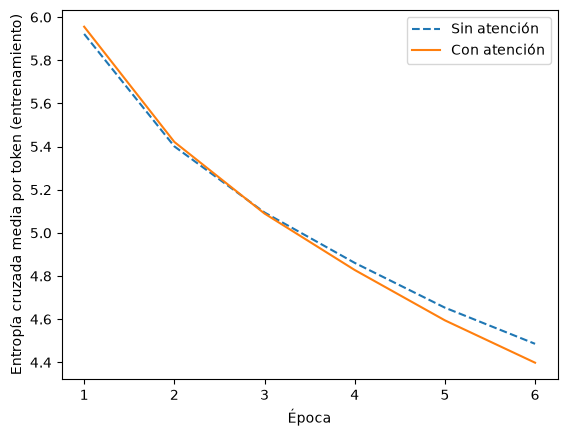

In [23]:
epochs = range(1, NUM_EPOCHS + 1)
plt.plot(epochs, history_plain, "--", label="Sin atención")
plt.plot(epochs, history_attn, label="Con atención")
plt.xlabel("Época")
plt.ylabel("Entropía cruzada media por token (entrenamiento)")
plt.legend()
plt.show()

## 5. Traducción y comparación

Búsqueda voraz con los dos modelos sobre los mismos ejemplos fijos de prueba (sin elegir solo los que salen bien).

In [24]:
@torch.no_grad()
def translate(sentence, model, max_new_tokens=50):
    model.eval()
    tokens = tokenize(sentence)
    source = torch.tensor([src_vocab.encode(tokens) + [EOS]], device=DEVICE)
    lengths = torch.tensor([source.size(1)])
    prediction = model.generate(source, lengths, max_new_tokens)
    words = tgt_vocab.decode(prediction[0].tolist())
    unknown = [token for token in tokens if token not in src_vocab.stoi]
    return " ".join(words), unknown


for en, es in test_pairs[:8]:
    plain, unknown = translate(" ".join(en), model_plain)
    attn, _ = translate(" ".join(en), model_attn)
    print("EN:", " ".join(en))
    print("Referencia:", " ".join(es))
    print("Sin atención:", plain)
    print("Con atención:", attn)
    print("Palabras desconocidas:", unknown)
    print()

EN: please rise , then , for this minute ' s silence .
Referencia: invito a todos a que nos pongamos de pie para guardar un minuto de silencio .
Sin atención: por tanto , , no se trata de un problema .
Con atención: por , , , , en de la .
Palabras desconocidas: []

EN: you will be aware from the press and television that there have been a number of bomb explosions and killings in sri lanka .
Referencia: sabrá usted por la prensa y la televisión que se han producido una serie de explosiones y asesinatos en sri lanka .
Sin atención: usted <unk> <unk> <unk> <unk> y <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .
Con atención: usted <unk> <unk> y <unk> y <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .
Palabras desconocidas: ['explosions', 'killings']

EN: why has there been no fire drill , either in the brussels parliament buildings or the strasbourg parliament buildings ?
Referencia: ¿ por qué no hemos tenido simulacros de incendio ni en

## 6. Mapa de la atención

Para algunas frases de prueba se dibuja la matriz $\alpha_{ij}$: cada fila es una palabra generada $y_i$ y cada columna una palabra de origen $h_j$. Cuanto más clara es la casilla, más atención presta el decodificador a esa palabra de origen al generar $y_i$.


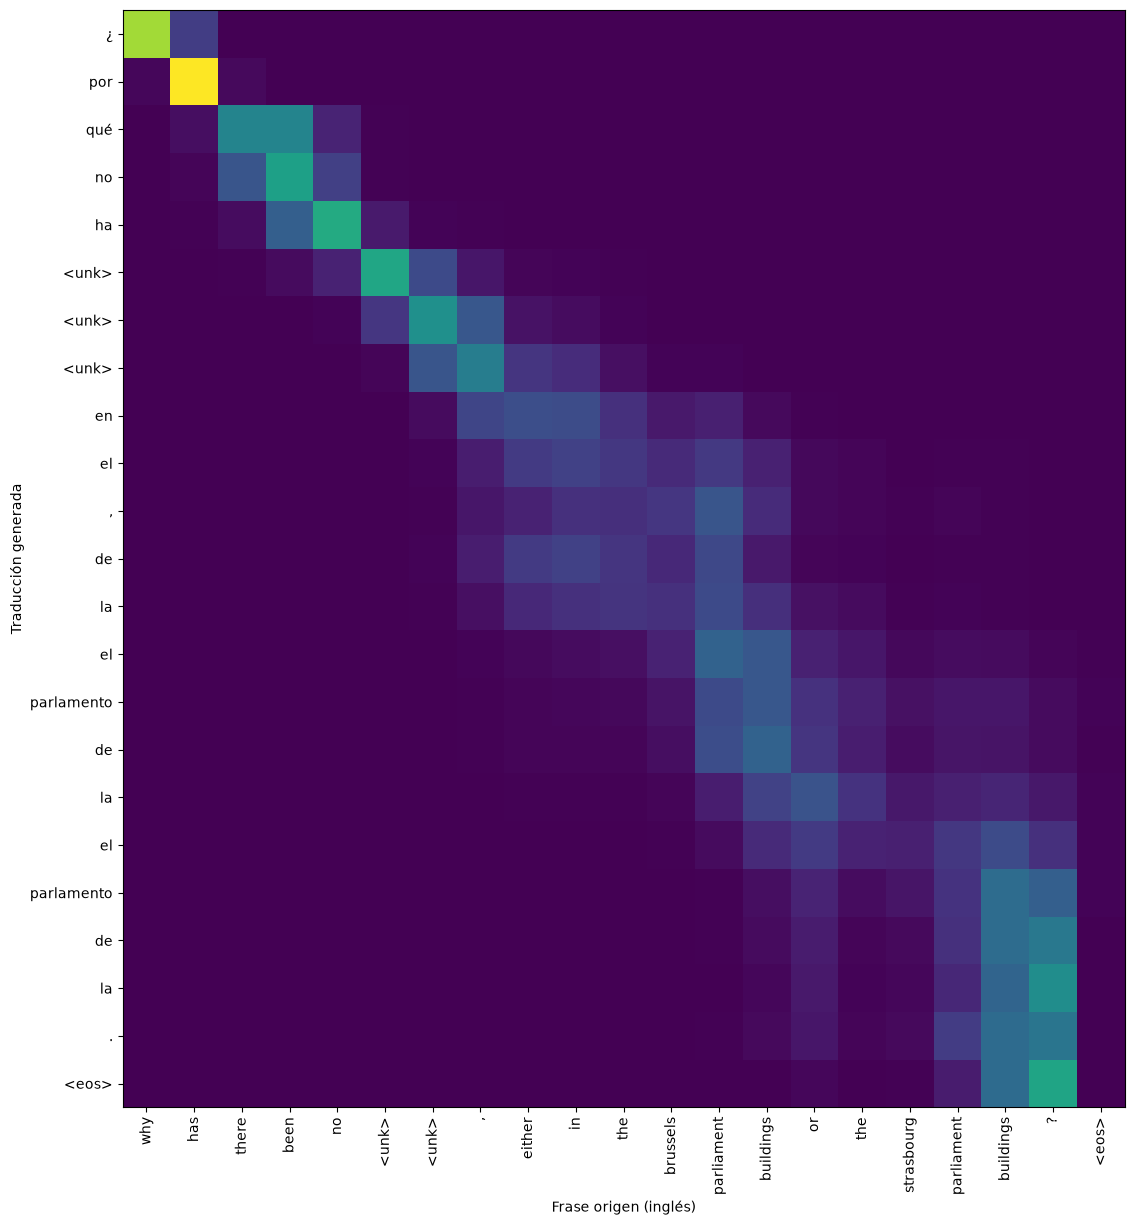

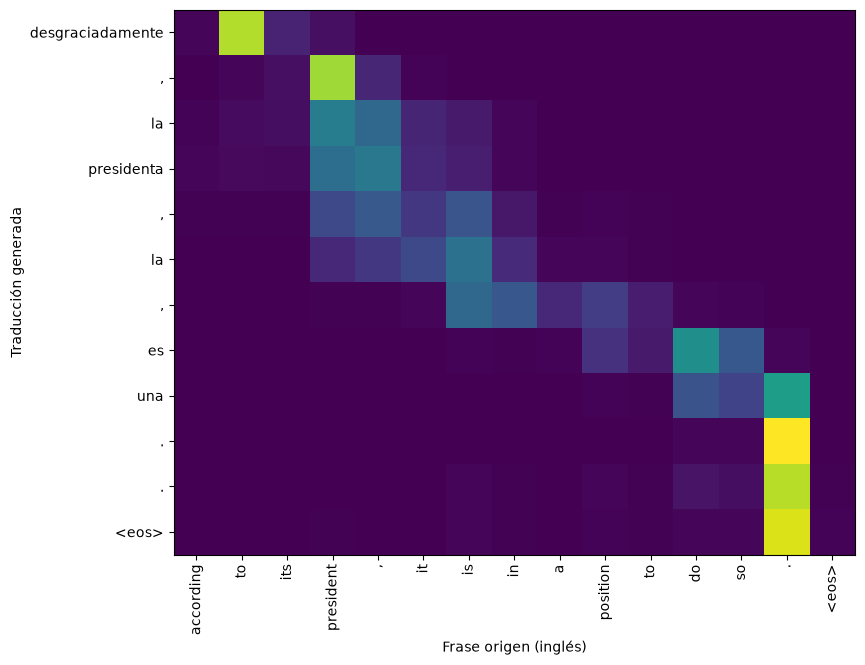

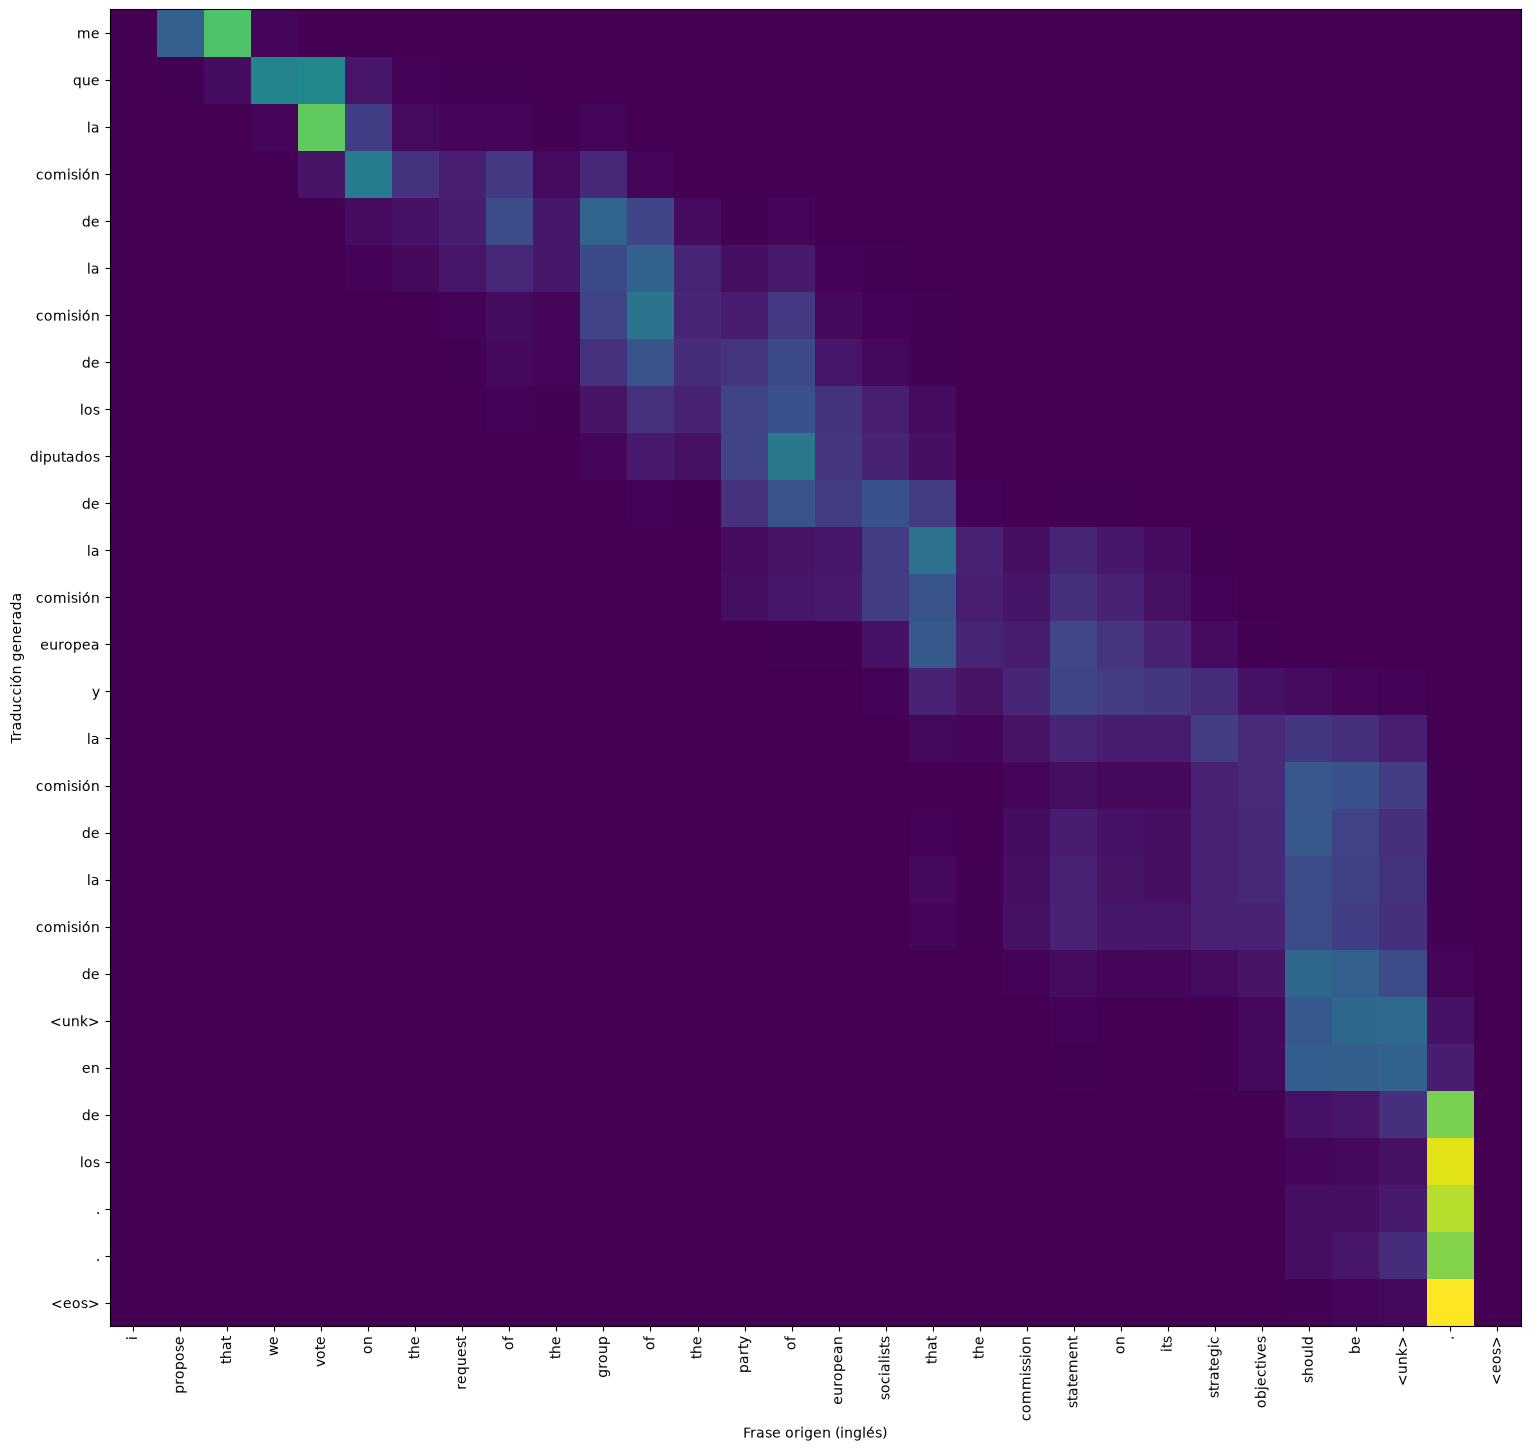

In [25]:
def plot_attention(en_tokens, model):
    source = torch.tensor([src_vocab.encode(en_tokens) + [EOS]], device=DEVICE)
    prediction, weights = model.generate(source, torch.tensor([source.size(1)]), 50,
                                         return_attention=True)
    ids = prediction[0].tolist()
    steps = ids.index(EOS) + 1 if EOS in ids else len(ids)   # hasta <eos> incluido
    out_words = [tgt_vocab.itos[i] for i in ids[:steps]]
    in_words = [w if w in src_vocab.stoi else "<unk>" for w in en_tokens] + ["<eos>"]

    fig, ax = plt.subplots(figsize=(0.45 * len(in_words) + 2, 0.45 * len(out_words) + 2))
    ax.imshow(weights[0, :steps].cpu(), cmap="viridis")
    ax.set_xticks(range(len(in_words)), in_words, rotation=90)
    ax.set_yticks(range(len(out_words)), out_words)
    ax.set_xlabel("Frase origen (inglés)")
    ax.set_ylabel("Traducción generada")
    plt.tight_layout()
    plt.show()


for en, _ in test_pairs[2:5]:
    plot_attention(en, model_attn)


## 7. Conclusiones

**Resultados**

| | Sin atención | Con atención |
|---|---|---|
| Pérdida de entrenamiento, última época | 4.486 | 4.398 |
| Tiempo medio por época | ≈ 110 s | ≈ 140 s |
| Parámetros | 7,590,624 | 7,918,560 |

- **Pérdida.** Las dos curvas son muy parecidas; el modelo con atención termina ligeramente por debajo (4.398 frente a 4.486). Al ser pérdida de entrenamiento con *teacher forcing*, no mide directamente la calidad de la traducción, por lo que la comparación se basa sobre todo en las traducciones y en los mapas de atención.
- **Traducciones.** Con solo 6 épocas ninguno de los dos modelos traduce bien, pero el modelo con atención sigue mejor la estructura de la frase origen: por ejemplo, en *"madam president, i would like to thank mr poettering…"* produce "señora presidenta , quisiera dar las gracias al sr ." y en *"why has there been no fire drill…"* acierta el comienzo "¿ por qué no ha…". En frases largas ambos modelos caen en repeticiones ("la comisión de la comisión…"). Las palabras desconocidas (`<unk>`) afectan a los dos modelos por igual.
- **Mapas de atención.** Se observa una alineación aproximadamente diagonal entre la frase origen y la traducción, incluso en la frase de 30 palabras, lo que indica que el decodificador aprende a recorrer la entrada en orden. Al principio de la frase la alineación es nítida ("¿ por qué" ↔ "why has", "presidenta" ↔ "president"), mientras que en las zonas centrales la atención se reparte entre varias palabras, coincidiendo con los errores y repeticiones. Los últimos tokens (".", `<eos>`) atienden al signo de puntuación final. Es decir, el modelo ya alinea correctamente aunque todavía no traduzca bien las palabras.
- **Coste.** La atención añade unos 330.000 parámetros ($W_1$, $v_a$ y la entrada ampliada de la LSTM del decodificador) y es aproximadamente un 30 % más lenta por época, porque en cada paso de decodificación calcula el score para las $T_x$ posiciones de la frase origen.
- **Limitaciones.** Se ha entrenado solo 6 épocas por tiempo de cómputo; con más épocas cabría esperar que la ventaja de la atención fuera mayor, sobre todo en frases largas. Además, a diferencia del artículo original, el encoder es unidireccional para mantener el mismo modelo base que el notebook anterior.
